In [2]:
import numpy as np
import math
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


# 2.1

p(x)-Koeffizienten [a,b,c] für ax^2+bx+c: [1.47624622 0.24203561 1.        ]
|f(1.2) - p(1.2)| (tatsächlich)       : 0.09612036445581218
Punktweise Schranke bei x=1.2         : 0.2364497951657807
max |x(x-1)(x-2)| auf [0,2]           : 0.38490017945975047
Obere Schranke für max. Fehler        : 0.4740081697527618
(extra) numerische Supremumsnäherung  : 0.21345663155041628 bei x≈ 1.606


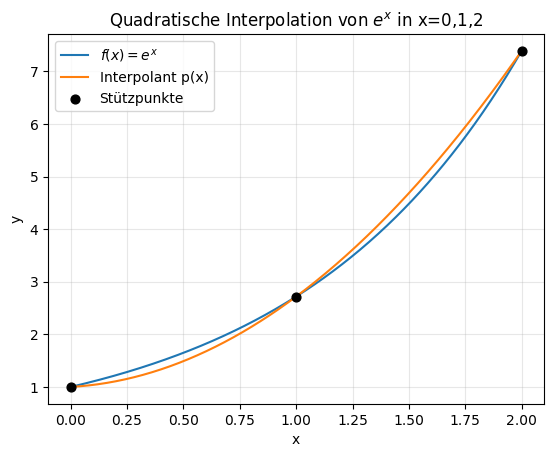

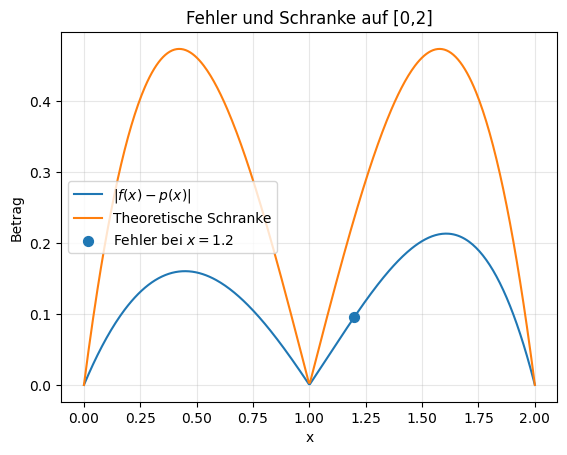

In [3]:


# Daten / Funktionen
f = np.exp
x_nodes = np.array([0.0, 1.0, 2.0])
y_nodes = np.array([1.0, math.e, math.e**2])

# Quadratischer Interpolant p(x) als Polynom (ax^2 + bx + c)
coeffs = np.polyfit(x_nodes, y_nodes, deg=2)   # [a, b, c]
p = lambda x: np.polyval(coeffs, x)

# Interpolationsfehler-Formel (n=2):
# |f(x) - p(x)| <= (max_{[0,2]} |f'''| / 3!) * |x(x-1)(x-2)|
# Für f(x)=e^x ist f'''=e^x, Maximum auf [0,2] ist e^2.
pointwise_bound = lambda x: (math.e**2 / 6.0) * np.abs(x*(x-1)*(x-2))

x0 = 1.2
err_at_12 = abs(f(x0) - p(x0))
bound_at_12 = pointwise_bound(x0)

# Maximale Schranke auf [0,2]
x_crit1 = 1.0 - 1.0/math.sqrt(3)
x_crit2 = 1.0 + 1.0/math.sqrt(3)
omega = lambda x: x*(x-1)*(x-2)
max_abs_omega = max(abs(omega(x_crit1)), abs(omega(x_crit2)))
max_err_upper_bound = (math.e**2/6.0) * max_abs_omega

# Numerische Supremumsnäherung
xs_dense = np.linspace(0, 2, 2001)
sup_err_numeric = np.max(np.abs(f(xs_dense) - p(xs_dense)))
x_sup = xs_dense[np.argmax(np.abs(f(xs_dense) - p(xs_dense)))]

print("p(x)-Koeffizienten [a,b,c] für ax^2+bx+c:", coeffs)
print("|f(1.2) - p(1.2)| (tatsächlich)       :", err_at_12)
print("Punktweise Schranke bei x=1.2         :", bound_at_12)
print("max |x(x-1)(x-2)| auf [0,2]           :", max_abs_omega)
print("Obere Schranke für max. Fehler        :", max_err_upper_bound)
print("(extra) numerische Supremumsnäherung  :", sup_err_numeric, "bei x≈", x_sup)

# Plot 1: f und p
xs = np.linspace(0, 2, 400)
plt.figure()
plt.plot(xs, f(xs), label=r"$f(x)=e^x$")
plt.plot(xs, p(xs), label="Interpolant p(x)")
plt.scatter(x_nodes, y_nodes, color="k", s=40, zorder=3, label="Stützpunkte")
plt.title("Quadratische Interpolation von $e^x$ in x=0,1,2")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Plot 2: Fehler und Schranke
err = np.abs(f(xs) - p(xs))
bound = pointwise_bound(xs)

plt.figure()
plt.plot(xs, err, label=r"$|f(x)-p(x)|$")
plt.plot(xs, bound, label="Theoretische Schranke")
plt.scatter([x0], [err_at_12], s=50, zorder=3, label=r"Fehler bei $x=1.2$")
plt.title("Fehler und Schranke auf [0,2]")
plt.xlabel("x")
plt.ylabel("Betrag")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# 2.2

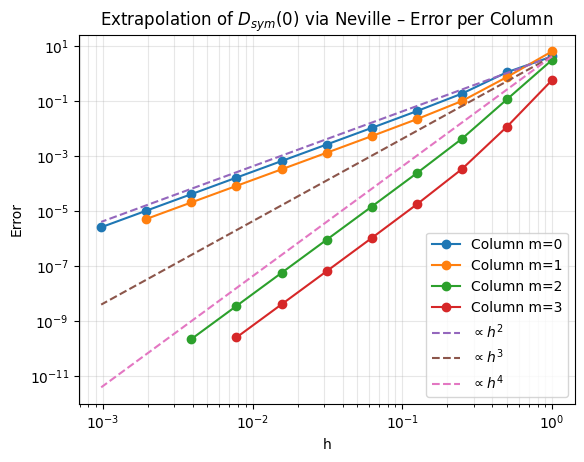

'\ndef est_order(hs, es):\n    # Ordnung p via e ~ C*h^p (letzte zwei Punkte)\n    return np.log(es[-1]/es[-2]) / np.log(hs[-1]/hs[-2])\n\nprint("True value f\'(pi/4) =", true_value)\nfor m in ms:\n    errs = np.abs(N[:(nmax + 1 - m), m] - true_value)\n    hs = h[:(nmax + 1 - m)]\n    # robustere Schätzung: verwende die letzten 5 Punkte und nimm die letzte Steigung\n    p_est = est_order(hs[-5:], errs[-5:])\n    print(f"Estimated order for column m={m}: ~{p_est:.2f}")'

In [4]:
# (a) Neville 
def neville_table(x, y, x_eval):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    n = len(x)
    N = np.zeros((n, n), dtype=float)
    N[:, 0] = y
    for m in range(1, n):
        for i in range(n - m):
            # rekursive Neville-Formel
            N[i, m] = ((x_eval - x[i + m]) * N[i, m - 1]
                       - (x_eval - x[i]) * N[i + 1, m - 1]) / (x[i] - x[i + m])
    return N

# (b) Problem setup 
def D_sym(f, x0, h):
    # symmetrischer Differenzenquotient
    return (f(x0 + h) - f(x0 - h)) / (2*h)

f = np.tan
x0 = math.pi/4
true_value = 1 / (math.cos(x0)**2)  # = 2

nmax = 10
h = 2.0 ** (-np.arange(0, nmax + 1))       # h_i = 2^{-i}, i = 0..nmax
y = np.array([D_sym(f, x0, hi) for hi in h])

# Neville table for extrapolation at h = 0
N = neville_table(h, y, x_eval=0.0)

# Error vs h for first 4 Neville columns 
ms = [0, 1, 2, 3]
plt.figure()
for m in ms:
    errs = np.abs(N[:(nmax + 1 - m), m] - true_value)
    plt.loglog(h[:(nmax + 1 - m)], errs, marker='o', label=f"Column m={m}")

# Reference lines ~ h^2, h^3, h^4 (scaled for visibility)
plt.loglog(h, (h**2) * (np.abs(y[0] - true_value) / (h[0]**2)), linestyle='--', label=r"$\propto h^2$")
plt.loglog(h, (h**3) * (np.abs(y[0] - true_value) / (h[0]**3)), linestyle='--', label=r"$\propto h^3$")
plt.loglog(h, (h**4) * (np.abs(y[0] - true_value) / (h[0]**4)), linestyle='--', label=r"$\propto h^4$")

plt.xlabel("h")
plt.ylabel("Error")
plt.title("Extrapolation of $D_{sym}(0)$ via Neville – Error per Column")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

# Extra plot: show the step sizes h_i - für mich!!!
"""plt.figure()
plt.semilogy(np.arange(0, nmax + 1), h, marker='o')
plt.xlabel("Index i")
plt.ylabel("Step size $h_i$")
plt.title("Step sizes $h_i = 2^{-i}$")
plt.grid(True, which="both", alpha=0.3)
plt.show()"""

# print observed orders - für mich!!!
"""
def est_order(hs, es):
    # Ordnung p via e ~ C*h^p (letzte zwei Punkte)
    return np.log(es[-1]/es[-2]) / np.log(hs[-1]/hs[-2])

print("True value f'(pi/4) =", true_value)
for m in ms:
    errs = np.abs(N[:(nmax + 1 - m), m] - true_value)
    hs = h[:(nmax + 1 - m)]
    # robustere Schätzung: verwende die letzten 5 Punkte und nimm die letzte Steigung
    p_est = est_order(hs[-5:], errs[-5:])
    print(f"Estimated order for column m={m}: ~{p_est:.2f}")"""


# 2.3

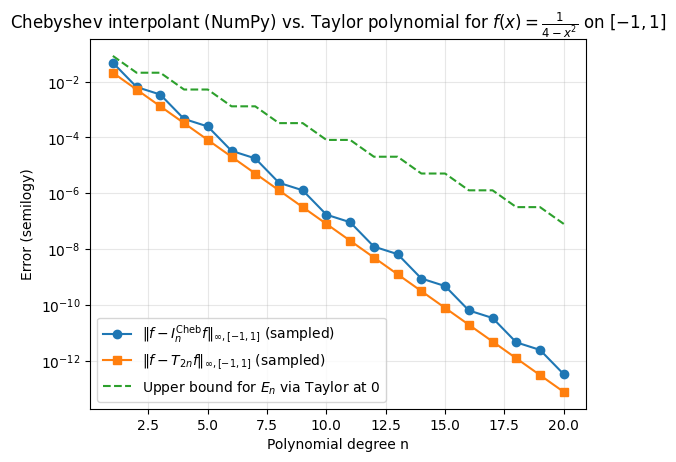

n | Chebyshev sup error (approx) | Taylor (deg 2n) sup error (approx) | Upper bound for best approx E_n
 1 | 4.762e-02 | 2.083e-02 | 8.333e-02
 2 | 6.410e-03 | 5.208e-03 | 2.083e-02
 3 | 3.436e-03 | 1.302e-03 | 2.083e-02
 4 | 4.604e-04 | 3.255e-04 | 5.208e-03
 5 | 2.467e-04 | 8.138e-05 | 5.208e-03
 6 | 3.306e-05 | 2.035e-05 | 1.302e-03
 7 | 1.771e-05 | 5.086e-06 | 1.302e-03
 8 | 2.373e-06 | 1.272e-06 | 3.255e-04
 9 | 1.272e-06 | 3.179e-07 | 3.255e-04
10 | 1.704e-07 | 7.947e-08 | 8.138e-05
11 | 9.131e-08 | 1.987e-08 | 8.138e-05
12 | 1.223e-08 | 4.967e-09 | 2.035e-05
13 | 6.556e-09 | 1.242e-09 | 2.035e-05
14 | 8.783e-10 | 3.104e-10 | 5.086e-06
15 | 4.707e-10 | 7.761e-11 | 5.086e-06
16 | 6.306e-11 | 1.940e-11 | 1.272e-06
17 | 3.380e-11 | 4.851e-12 | 1.272e-06
18 | 4.528e-12 | 1.213e-12 | 3.179e-07
19 | 2.426e-12 | 3.031e-13 | 3.179e-07
20 | 3.257e-13 | 7.577e-14 | 7.947e-08


In [5]:
from numpy.polynomial.chebyshev import Chebyshev

def f(x):
    return 1.0/(4.0 - x**2)

def cheb_nodes_first_kind(n):
    # n+1 Chebyshev nodes of the first kind on [-1,1]
    k = np.arange(n+1)
    return np.cos((2*k + 1) * np.pi / (2*(n+1)))

def best_approx_upper_bound(n):
    # Upper bound for min_{deg<=n} ||f-q||_∞ via Taylor at 0:
    # f(x)=sum_{k>=0} x^{2k}/4^{k+1}; with m=floor(n/2)
    # sup error <= (1/3)*4^{-(m+1)} on [-1,1]
    m = n//2
    return (1.0/3.0) * 4.0**(-(m+1))

def taylor_T_2n_values(n, x):
    # Taylor T_{2n} about 0
    x = np.asarray(x, dtype=float)
    res = np.zeros_like(x, dtype=float)
    for k in range(0, n+1):      # even powers up to 2n
        res += x**(2*k) / 4.0**(k+1)
    return res

ns = np.arange(1, 21)
x_test = np.linspace(-1, 1, 2000)   # grid to approximate sup norm

cheb_err, taylor_err, upper_E = [], [], []
for n in ns:
    # Exact degree-n Chebyshev interpolant via NumPy
    xk = cheb_nodes_first_kind(n)
    yk = f(xk)
    Pn = Chebyshev.fit(xk, yk, deg=n, domain=[-1, 1])   # exact when len(xk)=deg+1
    cheb_vals = Pn(x_test)
    t_vals = taylor_T_2n_values(n, x_test)

    cheb_err.append(np.max(np.abs(f(x_test) - cheb_vals)))
    taylor_err.append(np.max(np.abs(f(x_test) - t_vals)))
    upper_E.append(best_approx_upper_bound(n))

cheb_err = np.array(cheb_err)
taylor_err = np.array(taylor_err)
upper_E = np.array(upper_E)

# Plot
plt.figure()
plt.semilogy(ns, cheb_err, marker='o', label=r"$\|f - I_n^{\mathrm{Cheb}} f\|_{\infty,[-1,1]}$ (sampled)")
plt.semilogy(ns, taylor_err, marker='s', label=r"$\|f - T_{2n} f\|_{\infty,[-1,1]}$ (sampled)")
plt.semilogy(ns, upper_E, linestyle='--', label=r"Upper bound for $E_n$ via Taylor at 0")
plt.xlabel("Polynomial degree n")
plt.ylabel("Error (semilogy)")
plt.title(r"Chebyshev interpolant (NumPy) vs. Taylor polynomial for $f(x)=\frac{1}{4-x^2}$ on $[-1,1]$")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

# (Optional) print a small table
print("n | Chebyshev sup error (approx) | Taylor (deg 2n) sup error (approx) | Upper bound for best approx E_n")
for i, n in enumerate(ns):
    print(f"{n:2d} | {cheb_err[i]:.3e} | {taylor_err[i]:.3e} | {upper_E[i]:.3e}")


# 2.4

In [6]:
import time

def harmonic_sum(N):
    """Exact S(N) with Kahan compensaton."""
    s = 0.0
    c = 0.0
    for k in range(1, N+1):
        y = 1.0/k - c
        t = s + y
        c = (t - s) - y
        s = t
    return s

# Build and solve the 3x3 system from N=10,100,1000
Ns = np.array([10, 100, 1000], dtype=float)
S_vals = np.array([harmonic_sum(int(N)) for N in Ns])
A = np.column_stack([np.ones_like(Ns), 1/Ns, 1/Ns**2])
b = S_vals - np.log(Ns)
a0, a1, a2 = np.linalg.solve(A, b)

print("Fitted coefficients:")
print(f"a0 = {a0:.12f}")
print(f"a1 = {a1:.12f}")
print(f"a2 = {a2:.12f}")

# Approximation
def S_approx(N, a0=a0, a1=a1, a2=a2):
    N = float(N)
    return math.log(N) + a0 + a1/N + a2/N**2

# High-accuracy reference via Euler–Maclaurin (even powers only)
gamma = 0.5772156649015329
def S_em(N):
    N = float(N)
    return (math.log(N) + gamma
            + 1/(2*N) - 1/(12*N**2) + 1/(120*N**4)
            - 1/(252*N**6) + 1/(240*N**8))

# Errors for N=1e6 and 1e8
for N in [10**6, 10**8]:
    S_true = harmonic_sum(N) if N <= 10**6 else S_em(N)
    print(f"\nN={N:,}")
    print(f"approx  = {S_approx(N):.12f}")
    print(f"ref     = {S_true:.12f}")
    print(f"|error| = {abs(S_approx(N)-S_true):.3e}")

# Timings
def time_it(fn, *args, repeat=5):
    best = float("inf")
    for _ in range(repeat):
        t0 = time.time()
        fn(*args)
        best = min(best, time.time() - t0)
    return best

for N in [10**8, 10**9]:
    t = time_it(S_approx, N)
    print(f"\nApprox runtime for N={N:,}: {t*1e6:.1f} microseconds")

t_1e6 = time_it(harmonic_sum, 10**6, repeat=1)
print(f"\nDirect summation runtime for S(10^6): {t_1e6:.3f} s")
t_1e8 = time_it(harmonic_sum, 10**8, repeat=1)
print(f"\nDirect summation runtime for S(10^8): {t_1e8:.3f} s")
#t_1e9 = time_it(harmonic_sum, 10**9, repeat=1)
#print(f"\nDirect summation runtime for S(10^9): {t_1e9:.3f} s")
print("Direct S(10^8) or S(10^9) by summation is impractically slow.")


Fitted coefficients:
a0 = 0.577215665822
a1 = 0.499998986431
a2 = -0.083240349105

N=1,000,000
approx  = 14.392726723785
ref     = 14.392726722866
|error| = 9.196e-10

N=100,000,000
approx  = 18.997896414774
ref     = 18.997896413854
|error| = 9.206e-10

Approx runtime for N=100,000,000: 0.0 microseconds

Approx runtime for N=1,000,000,000: 0.0 microseconds

Direct summation runtime for S(10^6): 0.247 s

Direct summation runtime for S(10^8): 21.036 s
Direct S(10^8) or S(10^9) by summation is impractically slow.
